# Flame predictor: train, evaluate, save

This notebook trains the two models behind the web app's **Flame predictor** (`POST /predict` in `services/ml/app.py`),
shows how accurate they are, and saves them to `data/build/models.json` + `data/build/report.json` for the ML service.

| Model | Algorithm | Target |
|---|---|---|
| Extinction | Logistic regression **with pairwise interaction terms**, 40-member bootstrap ensemble | Does the droplet flame go out before the droplet is consumed? |
| Burn rate | Ridge regression, 40-member bootstrap ensemble | Burning-rate constant *k* (mm²/s) |

**Training data:** FLEX (PSI-69), ISS droplet-combustion runs with recorded outcomes.
**PSI-68 (FLEX-2):** see section 2. The public PSI table lists the *planned* test matrix only, with no per-run results, so it
cannot be used as labelled training data. It can still be used to see which planned conditions the model covers. If you obtain
a per-run FLEX-2 results file, section 2 merges it automatically.

Section **4b** compares the shipped models against other algorithms (bagging, random forest, boosting, SVM, kNN, neural nets
including PyTorch) under the same nested cross-validation. The interaction model won that comparison and replaced plain
logistic regression ("previous" in the tables).

Run top to bottom. The last section overwrites the model files; rebuild the `ml` container afterwards.

In [1]:
import json, pathlib, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (roc_auc_score, roc_curve, brier_score_loss, accuracy_score, balanced_accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay, r2_score, mean_absolute_error, mean_squared_error)
from sklearn.calibration import calibration_curve

ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / "pipeline" / "build.py").exists():   # works from the repo root or from notebooks/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "pipeline"))
import build as B          # reuse the pipeline's loaders and ensemble code, so the notebook and build.py stay identical
from sklearn.base import BaseEstimator


class Interactions(BaseEstimator):
    # The shipped extinction model: features + all pairwise products -> standardise -> logistic regression.
    # C is chosen by grouped CV on the training data it is given (so it is nested when used inside a CV loop).
    def fit(self, X, y, groups=None):
        Xe = B.expand(X)
        self.C_ = B.pick_c(Xe, y, groups)
        self.m_ = B.ext_pipe(self.C_).fit(Xe, y)
        return self

    def predict_proba(self, X):
        return self.m_.predict_proba(B.expand(X))

RAW, OUT = ROOT / "data" / "raw", ROOT / "data" / "build"
FEATS, RNG, N_BOOT, PSI = B.FEATS, B.RNG, B.N_BOOT, B.PSI_PER_ATM
pd.set_option("display.width", 160); plt.rcParams["figure.dpi"] = 110
print("repo:", ROOT); print("features:", FEATS)

repo: /repo
features: ['heptane', 'o2', 'p_atm', 'co2', 'he', 'd0']


## 1. FLEX (PSI-69) data

In [2]:
d = B.flex_frame()
d["source"] = "FLEX (PSI-69)"
print(d.shape)
display(pd.crosstab(d.fuel, d.end, margins=True))
d[["id", "fuel", "o2", "p_atm", "co2", "he", "d0", "k", "end"]].head()

(274, 18)


end,Completion,Disruption,Extinction,All
fuel,,,,
Heptane,19,38,60,117
Methanol,8,23,126,157
All,27,61,186,274


,id,fuel,o2,p_atm,co2,he,d0,k,end
0,20CAL08,Methanol,0.21,0.996974,0.0,0.0,1.69,0.52,Disruption
1,20CAL10,Methanol,0.21,1.002632,0.0,0.0,1.86,0.60,Extinction
2,20CAL12,Methanol,0.21,1.005526,0.0,0.0,1.61,0.58,Extinction
3,30CAL02,Methanol,0.21,1.000000,0.0,0.0,2.06,0.60,Extinction
4,30CAL03,Methanol,0.21,1.000000,0.0,0.0,1.92,0.48,Extinction


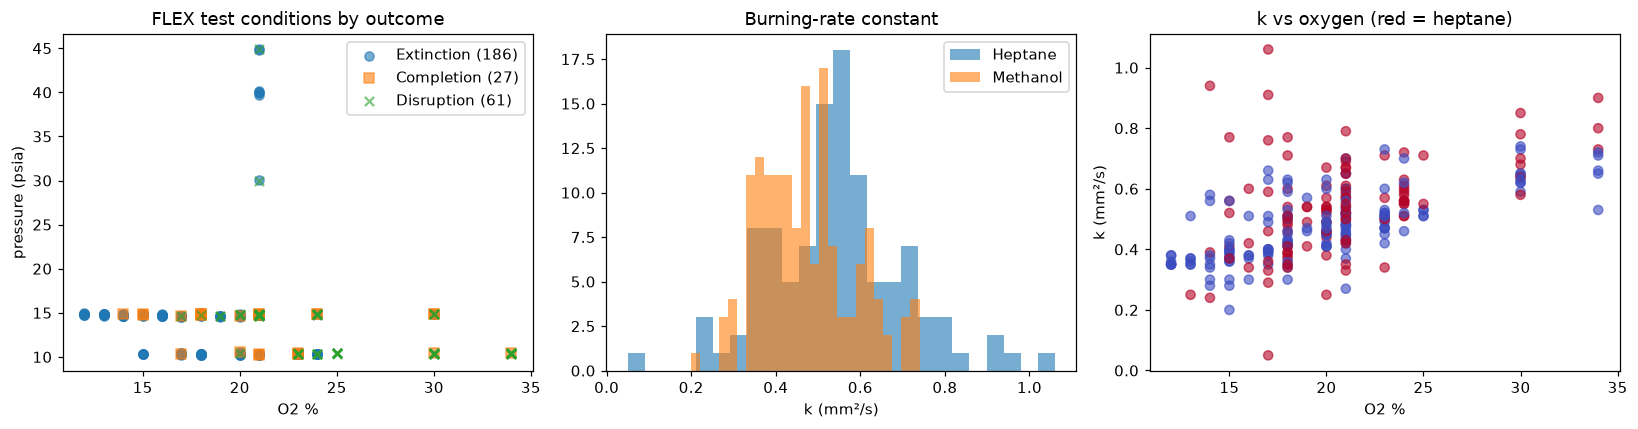

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for end, m in [("Extinction", "o"), ("Completion", "s"), ("Disruption", "x")]:
    s = d[d.end == end]
    ax[0].scatter(s.o2 * 100, s.p_atm * PSI, marker=m, alpha=.6, label=f"{end} ({len(s)})")
ax[0].set(xlabel="O2 %", ylabel="pressure (psia)", title="FLEX test conditions by outcome"); ax[0].legend()
for fuel, g in d.groupby("fuel"):
    ax[1].hist(g.k.dropna(), bins=25, alpha=.6, label=fuel)
ax[1].set(xlabel="k (mm²/s)", title="Burning-rate constant"); ax[1].legend()
ax[2].scatter(d.o2 * 100, d.k, c=(d.fuel == "Heptane"), cmap="coolwarm", alpha=.6)
ax[2].set(xlabel="O2 %", ylabel="k (mm²/s)", title="k vs oxygen (red = heptane)")
plt.tight_layout(); plt.show()

## 2. PSI-68 (FLEX-2)

The PSI repository's experimental table for PSI-68 (`PSI-68_Experimental_table_Flex2.csv`) holds 8 rows: one per fuel, each
listing *ranges* of planned O2, pressure, diameter and flow. It has no outcome or burning rate, so it has no labels to train on.

Two useful things we *can* do with it:
1. **Coverage check:** which planned FLEX-2 conditions fall inside the range the model was trained on.
2. **Merge real runs when available:** drop a per-run results CSV at `data/raw/PSI-68_runs.csv` using the **same columns as the
   PSI-69 table**, and the next cell adds those rows. Only heptane and methanol rows are kept, because the feature set encodes
   fuel as heptane vs methanol. Other FLEX-2 fuels (decane, ethanol, iso-octane…) would need new fuel features and an app change.

,Sample (Fuel Type),Initial Droplet Diameter (mm),Ambient Gas Mixture,Oxygen Mole Fraction,Ambient Pressure (atm),Ambient Temperature (C),Flow Velocity (cm/s)
0,IsoOctane (pure),1.5 - 5,O2/N2 or O2/He,0.17; 0.21;0.25; 0.3,0.5; 1.0; 1.5; 2.0; or 3.0,25,0.1 - 5
1,n-Octane (pure),1.5 - 5,O2/N2 or O2/He,0.17; 0.21;0.25; 0.3,0.5; 1.0; 1.5; 2.0; or 3.0,25,0.1 - 5
2,Heptane (pure),1.5 - 5,O2/N2 or O2/He,0.17; 0.21;0.25; 0.3,0.5; 1.0; 1.5; 2.0; or 3.0,25,0.1 - 5
3,Decane (pure),1.5 - 5,O2/N2 or O2/He,0.17; 0.21;0.25; 0.3,0.5; 1.0; 1.5; 2.0; or 3.0,25,0.1 - 5
4,Ethanol (pure),1.5 - 5,O2/N2 or O2/He,0.17; 0.21;0.25; 0.3,0.5; 1.0; 1.5; 2.0; or 3.0,25,0.1 - 5
5,Propanol (95%) Glycerol (5%) (mixture),1.5 - 5,O2/N2 or O2/He,0.17; 0.21;0.25; 0.3,0.5; 1.0; 1.5; 2.0; or 3.0,25,0.1 - 5
6,Heptane (50%) IsoOctane (50%) (mixture),1.5 - 5,O2/N2 or O2/He,0.17; 0.21;0.25; 0.3,0.5; 1.0; 1.5; 2.0; or 3.0,25,0.1 - 5
7,Propanol (80%) Glycerol (20%) (mixture),1.5 - 5,O2/N2 or O2/He,0.17; 0.21;0.25; 0.3,0.5; 1.0; 1.5; 2.0; or 3.0,25,0.1 - 5


FLEX training range: O2 12-34 %, pressure 10.2-44.9 psia
planned FLEX-2 points: 160; inside O2/pressure range: 128; inside range AND a fuel the model knows: 16


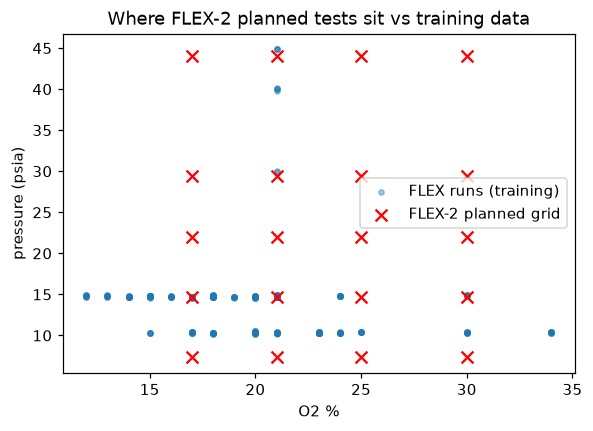

In [4]:
plan = pd.read_csv(RAW / "PSI-68_Experimental_table_Flex2.csv", encoding="latin-1")
display(plan)
pts = pd.DataFrame(B.flex2())[["fuel", "o2_pct", "pressure_psia"]]
dom = d.dropna(subset=FEATS)
o2_lo, o2_hi = dom.o2.min() * 100, dom.o2.max() * 100
p_lo, p_hi = dom.p_atm.min() * PSI, dom.p_atm.max() * PSI
pts["inside_FLEX_range"] = pts.o2_pct.between(o2_lo, o2_hi) & pts.pressure_psia.between(p_lo, p_hi)
pts["fuel_supported"] = pts.fuel.str.startswith(("Heptane (pure)",))
print(f"FLEX training range: O2 {o2_lo:.0f}-{o2_hi:.0f} %, pressure {p_lo:.1f}-{p_hi:.1f} psia")
print(f"planned FLEX-2 points: {len(pts)}; inside O2/pressure range: {pts.inside_FLEX_range.sum()}; "
      f"inside range AND a fuel the model knows: {(pts.inside_FLEX_range & pts.fuel_supported).sum()}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(dom.o2 * 100, dom.p_atm * PSI, s=12, alpha=.4, label="FLEX runs (training)")
u = pts.drop_duplicates(["o2_pct", "pressure_psia"])
ax.scatter(u.o2_pct, u.pressure_psia, marker="x", c="red", s=60, label="FLEX-2 planned grid")
ax.set(xlabel="O2 %", ylabel="pressure (psia)", title="Where FLEX-2 planned tests sit vs training data"); ax.legend()
plt.show()

In [5]:
runs = RAW / "PSI-68_runs.csv"
if runs.exists():
    f2 = pd.read_csv(runs, encoding="latin-1")
    f2.columns = ["test", "id", "date", "gmt", "fuel", "p_mmHg", "o2", "n2", "co2", "he", "d0", "d_ext", "k", "t_burn", "end"]
    for c in ["d0", "d_ext", "t_burn", "k"]:
        f2[c] = pd.to_numeric(f2[c], errors="coerce")
    f2.loc[f2.p_mmHg <= 0, "p_mmHg"] = np.nan
    f2["p_atm"] = f2.p_mmHg / 760
    f2["fuel"] = f2.fuel.str.strip()
    f2["end"] = f2.end.str.strip()
    dropped = f2[~f2.fuel.isin(["Heptane", "Methanol"])]
    f2 = f2[f2.fuel.isin(["Heptane", "Methanol"])].copy()
    f2["heptane"] = (f2.fuel == "Heptane").astype(int)
    f2["id"] = "F2-" + f2.id.astype(str)
    f2["source"] = "FLEX-2 (PSI-68)"
    print(f"FLEX-2 runs added: {len(f2)}; dropped (fuel not in model): {len(dropped)} {sorted(dropped.fuel.unique())}")
    d = pd.concat([d, f2], ignore_index=True)
else:
    print("No data/raw/PSI-68_runs.csv found: training on FLEX (PSI-69) only.")
print(d.source.value_counts().to_string())

No data/raw/PSI-68_runs.csv found: training on FLEX (PSI-69) only.
source
FLEX (PSI-69)    274


## 3. Training sets

* **Extinction** uses runs that ended in *Extinction* or *Completion*. *Disruption* (the droplet broke apart) says nothing
  about flammability, so those runs are excluded.
* **Burn rate** uses every run with a recorded *k*.

In [6]:
dd = d.dropna(subset=FEATS)
c = dd[dd.end.isin(["Extinction", "Completion"])]
r = dd.dropna(subset=["k"])
Xc, yc, gc = c[FEATS].to_numpy(float), (c.end == "Extinction").to_numpy(int), c.date.to_numpy()
Xr, yr, gr = r[FEATS].to_numpy(float), r.k.to_numpy(float), r.date.to_numpy()
print(f"extinction: {len(yc)} runs, {yc.sum()} extinctions ({yc.mean():.0%}), {len(set(gc))} test dates")
print(f"burn rate : {len(yr)} runs, k mean {yr.mean():.3f} mm²/s, {len(set(gr))} test dates")
print(f"disruption runs excluded: {(dd.end == 'Disruption').sum()}")

extinction: 206 runs, 179 extinctions (87%), 73 test dates
burn rate : 257 runs, k mean 0.502 mm²/s, 80 test dates
disruption runs excluded: 55


## 4. How accurate is it? (out-of-fold cross-validation)

5-fold **GroupKFold grouped by test date**: runs from the same day never sit on both sides of a split, so the score is not
inflated by near-duplicate repeats. Every prediction below was made by a model that never saw that run.

The linear models are compared with gradient boosting and a *naive* baseline that always predicts the training-fold average.

In [7]:
def oof(make, X, y, g, proba):
    p = np.zeros(len(y))
    for tr, te in GroupKFold(n_splits=5).split(X, y, g):
        if make is None:
            p[te] = y[tr].mean(); continue
        m = make()
        m.fit(X[tr], y[tr], **({"groups": g[tr]} if isinstance(m, Interactions) else {}))
        p[te] = m.predict_proba(X[te])[:, 1] if proba else m.predict(X[te])
    return p

gbk = dict(n_estimators=120, max_depth=2, learning_rate=0.06, subsample=0.8, random_state=RNG)
clf = {"Logistic + interactions (shipped)": Interactions,
       "Logistic regression (previous)": lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
       "Gradient boosting": lambda: GradientBoostingClassifier(**gbk),
       "Naive (base rate)": None}
P = {k: oof(m, Xc, yc, gc, True) for k, m in clf.items()}

rows = []
for k, p in P.items():
    rows.append({"model": k, "AUC": roc_auc_score(yc, p) if p.std() > 0 else 0.5, "Brier": brier_score_loss(yc, p),
                 "accuracy@0.5": accuracy_score(yc, p >= .5), "balanced acc@0.5": balanced_accuracy_score(yc, p >= .5)})
clf_scores = pd.DataFrame(rows).set_index("model").round(3)
clf_scores

,AUC,Brier,accuracy@0.5,balanced acc@0.5
model,,,,
Logistic + interactions (shipped),0.880,0.079,0.913,0.698
Logistic regression (previous),0.819,0.089,0.888,0.590
Gradient boosting,0.777,0.100,0.879,0.631
Naive (base rate),0.423,0.114,0.869,0.500


*Reading the table:* about 87% of runs extinguish, so **plain accuracy is misleading**: predicting "extinction" every time already
scores ~0.87. **AUC** (ranking quality, 0.5 = chance) and **balanced accuracy** (average recall over both classes) are the
honest numbers. **Brier** is the mean squared error of the probability (lower is better).

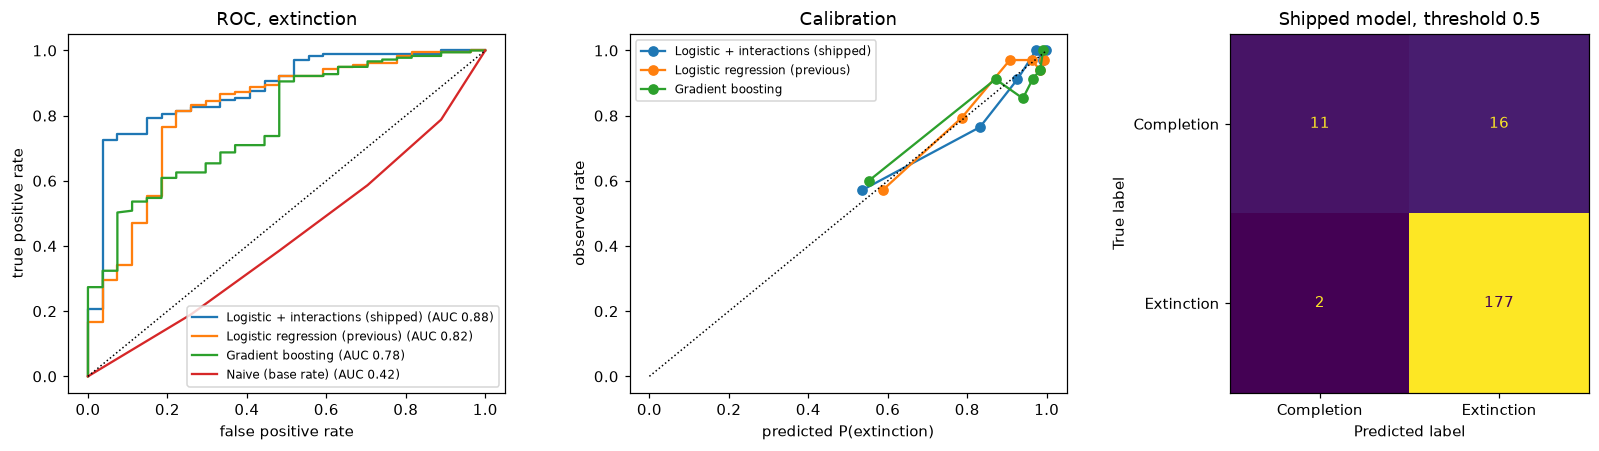

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for k, p in P.items():
    if p.std() > 0:
        fpr, tpr, _ = roc_curve(yc, p); ax[0].plot(fpr, tpr, label=f"{k} (AUC {roc_auc_score(yc, p):.2f})")
ax[0].plot([0, 1], [0, 1], "k:", lw=1); ax[0].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC, extinction"); ax[0].legend(fontsize=8)
for k, p in list(P.items())[:3]:
    fr, mp = calibration_curve(yc, p, n_bins=6, strategy="quantile"); ax[1].plot(mp, fr, "o-", label=k)
ax[1].plot([0, 1], [0, 1], "k:", lw=1); ax[1].set(xlabel="predicted P(extinction)", ylabel="observed rate", title="Calibration"); ax[1].legend(fontsize=8)
ConfusionMatrixDisplay(confusion_matrix(yc, P["Logistic + interactions (shipped)"] >= .5),
                       display_labels=["Completion", "Extinction"]).plot(ax=ax[2], colorbar=False)
ax[2].set_title("Shipped model, threshold 0.5")
plt.tight_layout(); plt.show()

,R²,MAE (mm²/s),RMSE (mm²/s)
model,,,
Ridge regression (shipped),0.6813,0.0497,0.0776
Gradient boosting,0.6155,0.0579,0.0853
Naive (mean),-0.0281,0.1082,0.1394


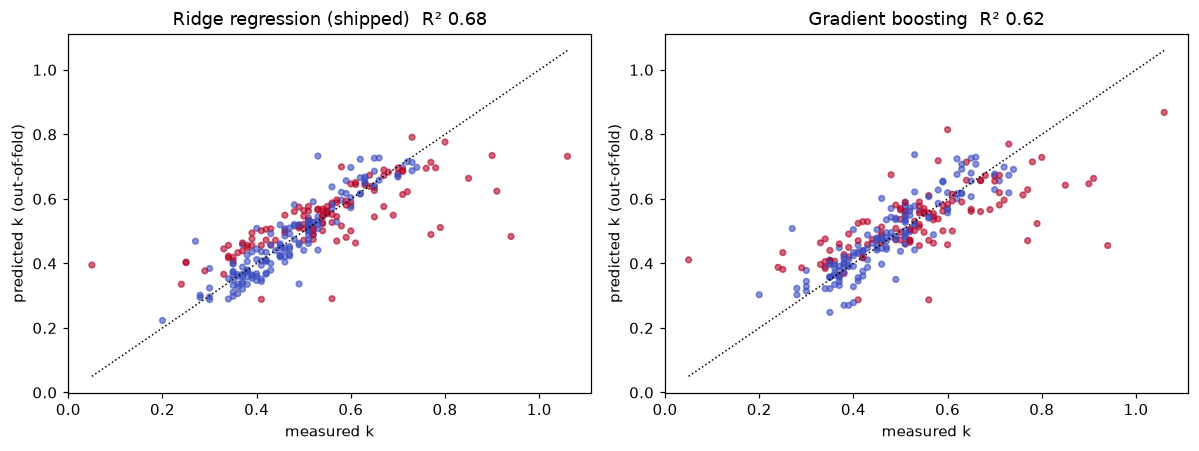

In [9]:
reg = {"Ridge regression (shipped)": lambda: make_pipeline(StandardScaler(), Ridge()),
       "Gradient boosting": lambda: GradientBoostingRegressor(**gbk),
       "Naive (mean)": None}
R = {k: oof(m, Xr, yr, gr, False) for k, m in reg.items()}
reg_scores = pd.DataFrame([{"model": k, "R²": r2_score(yr, p), "MAE (mm²/s)": mean_absolute_error(yr, p),
                            "RMSE (mm²/s)": mean_squared_error(yr, p) ** .5} for k, p in R.items()]).set_index("model").round(4)
display(reg_scores)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for a, k in zip(ax, list(R)[:2]):
    a.scatter(yr, R[k], c=r.heptane, cmap="coolwarm", alpha=.6, s=14)
    lim = [min(yr.min(), R[k].min()), max(yr.max(), R[k].max())]
    a.plot(lim, lim, "k:", lw=1); a.set(xlabel="measured k", ylabel="predicted k (out-of-fold)", title=f"{k}  R² {r2_score(yr, R[k]):.2f}")
plt.tight_layout(); plt.show()

## 4b. Model comparison: which algorithm is best?

The same task with up to 16 algorithms, from simple to flexible:

| Family | Models |
|---|---|
| Linear | logistic (previous) / ridge (**shipped**), class-balanced logistic, logistic (**shipped**) / ridge with pairwise interaction terms |
| Kernel & distance | SVM (RBF kernel), k-nearest neighbours |
| Single tree | decision tree |
| **Bagging** | bagged trees, random forest, extra trees |
| **Boosting** | AdaBoost, gradient boosting, histogram gradient boosting |
| Neural nets | scikit-learn and PyTorch MLPs trained from scratch, and MLPs *pre-trained on burning rate, then fine-tuned* on extinction. The PyTorch rows appear only where torch can load. |

**Protocol, kept fair and leak-free:**
* Outer loop: 5 folds grouped by test date (stratified by outcome for extinction), **repeated 3× with different shuffles**.
  Every number below is mean ± sd over the 3 repeats.
* Hyper-parameters for the tunable models are picked by an **inner** 3-fold grouped grid search that runs only inside each
  training fold (nested CV). The test fold is never used for tuning.
* The pre-trained/fine-tuned net pre-trains on burning-rate data **from the training dates only**, so no information from the
  test fold leaks in through the related target.

**About "fine-tuning":** there is no public pre-trained model for droplet combustion, so classic fine-tuning (start from someone
else's weights) does not apply. The closest honest version is *transfer between our own two targets*: learn a representation by
predicting burning rate (257 runs), then fine-tune it to predict extinction (206 runs).

**Metrics:** the app shows a *probability*, so for extinction the main metric is **Brier score** (probability error, lower is
better), with **AUC** (ranking) and **log loss** alongside. *Balanced accuracy* is at a 0.5 cutoff. *AP(completion)* is the
average precision for spotting the rare "burned to completion" class (chance ≈ 0.13).

In [10]:
import time, warnings
from sklearn.base import BaseEstimator
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor, ExtraTreesClassifier, ExtraTreesRegressor,
                              BaggingClassifier, BaggingRegressor, AdaBoostClassifier, AdaBoostRegressor,
                              HistGradientBoostingClassifier, HistGradientBoostingRegressor)
from sklearn.preprocessing import PolynomialFeatures
from sklearn.svm import SVC, SVR
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.metrics import log_loss, average_precision_score
from sklearn.neural_network import MLPClassifier, MLPRegressor
warnings.filterwarnings("ignore")
try:
    import torch, torch.nn as nn
    torch.set_num_threads(4); HAS_TORCH = True
except Exception as e:      # e.g. Windows Application Control blocking torch's DLLs
    HAS_TORCH = False
    print(f"PyTorch unavailable here ({type(e).__name__}: {e}).\n-> torch models skipped; the scikit-learn neural nets still run.")


class SkFineTunedMLP(BaseEstimator):
    # scikit-learn version of pre-train -> fine-tune: an MLPRegressor learns burning rate, its hidden layers are copied into an
    # MLPClassifier, which is then fine-tuned on extinction at a low learning rate. Averaged over n_models seeds.
    def __init__(self, pretrain=None, hidden=(32, 32), alpha=1e-1, lr=3e-4, n_models=5, seed=0):
        self.pretrain, self.hidden, self.alpha, self.lr, self.n_models, self.seed = pretrain, hidden, alpha, lr, n_models, seed

    def fit(self, X, y):
        Xp, kp = self.pretrain
        self.sc_ = StandardScaler().fit(np.vstack([X, Xp]))
        Xs, Xps, kz = self.sc_.transform(X), self.sc_.transform(Xp), (kp - kp.mean()) / kp.std()
        self.models_ = []
        for s in range(self.n_models):
            pre = MLPRegressor(hidden_layer_sizes=self.hidden, alpha=self.alpha, max_iter=2000, random_state=self.seed + s).fit(Xps, kz)
            m = MLPClassifier(hidden_layer_sizes=self.hidden, alpha=self.alpha, learning_rate_init=self.lr, max_iter=1000, warm_start=True,
                              random_state=self.seed + s)
            two = [int(np.argmax(y == 0)), int(np.argmax(y == 1))]   # one row of each class
            m.partial_fit(Xs[two], y[two], classes=[0, 1])           # allocate the weight matrices
            for i in range(len(self.hidden)):                       # transplant the pre-trained hidden layers
                m.coefs_[i], m.intercepts_[i] = pre.coefs_[i].copy(), pre.intercepts_[i].copy()
            self.models_.append(m.fit(Xs, y))                      # fine-tune all layers on extinction
        return self

    def predict_proba(self, X):
        p = np.mean([m.predict_proba(self.sc_.transform(X))[:, 1] for m in self.models_], 0)
        return np.c_[1 - p, p]


class TorchMLP(BaseEstimator):
    # Small MLP ensemble (n_models nets, different seeds), full-batch AdamW with weight decay.
    # pretrain=(X, k): first train the body to predict burning rate, then fine-tune body + a fresh head on the real target,
    # with the body learning 10x slower so the pre-trained features are adjusted rather than overwritten.
    def __init__(self, task="clf", hidden=32, depth=2, dropout=0.1, wd=1e-2, lr=1e-2, epochs=300, n_models=5, seed=0, pretrain=None):
        self.task, self.hidden, self.depth, self.dropout, self.wd = task, hidden, depth, dropout, wd
        self.lr, self.epochs, self.n_models, self.seed, self.pretrain = lr, epochs, n_models, seed, pretrain

    def _net(self, d):
        layers, h = [], d
        for _ in range(self.depth):
            layers += [nn.Linear(h, self.hidden), nn.SiLU(), nn.Dropout(self.dropout)]; h = self.hidden
        return nn.Sequential(*layers), nn.Linear(h, 1)

    def _train(self, body, head, X, y, loss, groups):
        opt = torch.optim.AdamW(groups, weight_decay=self.wd)
        body.train(); head.train()
        for _ in range(self.epochs):
            opt.zero_grad(); loss(head(body(X)).squeeze(1), y).backward(); opt.step()

    def fit(self, X, y):
        T = lambda a: torch.tensor(np.asarray(a, float), dtype=torch.float32)
        self.sc_ = StandardScaler().fit(X if self.pretrain is None else np.vstack([X, self.pretrain[0]]))
        Xt, yt = T(self.sc_.transform(X)), T(y)
        if self.task == "reg":
            self.ym_, self.ys_ = float(np.mean(y)), float(np.std(y)) or 1.0; yt = (yt - self.ym_) / self.ys_
        loss = nn.BCEWithLogitsLoss() if self.task == "clf" else nn.MSELoss()
        self.models_ = []
        for s in range(self.n_models):
            torch.manual_seed(self.seed + s)
            body, head = self._net(X.shape[1])
            if self.pretrain is not None:
                Xp, kp = self.pretrain
                kp = (np.asarray(kp) - np.mean(kp)) / np.std(kp)
                ph = nn.Linear(self.hidden, 1)
                self._train(body, ph, T(self.sc_.transform(Xp)), T(kp), nn.MSELoss(),
                            [{"params": [*body.parameters(), *ph.parameters()], "lr": self.lr}])
                groups = [{"params": body.parameters(), "lr": self.lr / 10}, {"params": head.parameters(), "lr": self.lr}]
            else:
                groups = [{"params": [*body.parameters(), *head.parameters()], "lr": self.lr}]
            self._train(body, head, Xt, yt, loss, groups)
            body.eval(); head.eval(); self.models_.append((body, head))
        return self

    def _out(self, X):
        Xt = torch.tensor(self.sc_.transform(X), dtype=torch.float32)
        with torch.no_grad():
            o = np.stack([h(b(Xt)).squeeze(1).numpy() for b, h in self.models_])
        return o

    def predict_proba(self, X):
        p = (1 / (1 + np.exp(-self._out(X)))).mean(0)
        return np.c_[1 - p, p]

    def predict(self, X):
        return self._out(X).mean(0) * self.ys_ + self.ym_ if self.task == "reg" else (self.predict_proba(X)[:, 1] >= .5).astype(int)


def tuned(est, grid, clf):
    return GridSearchCV(est, grid, cv=GroupKFold(3), n_jobs=-1,
                        scoring="neg_brier_score" if clf else "neg_mean_absolute_error")

def with_dates(fn):          # factory that needs the training-fold test dates (for leak-free pre-training)
    fn.needs_dates = True
    return fn

S = lambda *steps: make_pipeline(StandardScaler(), *steps)
gb_grid = {"n_estimators": [60, 120, 240], "max_depth": [1, 2, 3]}
rf_grid = {"max_depth": [3, 6, None], "min_samples_leaf": [1, 5, 10]}

CLF = {
    "Logistic regression (previous)": lambda: S(LogisticRegression(max_iter=1000)),
    "Logistic, class-balanced": lambda: S(LogisticRegression(max_iter=1000, class_weight="balanced")),
    "Logistic + interactions (shipped)": Interactions,
    "SVM (RBF)": lambda: tuned(S(SVC(probability=True, random_state=RNG)), {"svc__C": [.3, 1, 3], "svc__gamma": ["scale", .05]}, True),
    "k-nearest neighbours": lambda: tuned(S(KNeighborsClassifier(weights="distance")), {"kneighborsclassifier__n_neighbors": [5, 10, 20, 40]}, True),
    "Decision tree": lambda: tuned(DecisionTreeClassifier(random_state=RNG), {"max_depth": [2, 3, 4], "min_samples_leaf": [5, 10, 20]}, True),
    "Bagging (trees)": lambda: BaggingClassifier(DecisionTreeClassifier(min_samples_leaf=5), n_estimators=200, random_state=RNG, n_jobs=-1),
    "Random forest": lambda: tuned(RandomForestClassifier(n_estimators=300, random_state=RNG), rf_grid, True),
    "Extra trees": lambda: tuned(ExtraTreesClassifier(n_estimators=300, random_state=RNG), rf_grid, True),
    "AdaBoost": lambda: tuned(AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), random_state=RNG),
                              {"n_estimators": [50, 150], "learning_rate": [.1, .5]}, True),
    "Gradient boosting": lambda: tuned(GradientBoostingClassifier(learning_rate=.06, subsample=.8, random_state=RNG), gb_grid, True),
    "Hist. gradient boosting": lambda: tuned(HistGradientBoostingClassifier(max_iter=200, random_state=RNG),
                                             {"max_depth": [2, 3], "learning_rate": [.03, .1], "l2_regularization": [0, 1]}, True),
    "Neural net (sklearn MLP)": lambda: tuned(S(MLPClassifier(hidden_layer_sizes=(32, 32), max_iter=2000, random_state=RNG)),
                                              {"mlpclassifier__alpha": [.01, .1, 1]}, True),
    "Neural net (sklearn), pre-trained on k → fine-tuned": with_dates(
        lambda dates: SkFineTunedMLP(pretrain=(Xr[np.isin(gr, dates)], yr[np.isin(gr, dates)]))),
    "Naive (base rate)": None,
}
if HAS_TORCH:
    CLF["Neural net (torch MLP)"] = lambda: TorchMLP("clf")
    CLF["Neural net (torch), pre-trained on k → fine-tuned"] = with_dates(
        lambda dates: TorchMLP("clf", pretrain=(Xr[np.isin(gr, dates)], yr[np.isin(gr, dates)])))
REG = {
    "Ridge regression (shipped)": lambda: S(Ridge()),
    "Ridge + interactions": lambda: tuned(make_pipeline(PolynomialFeatures(2, include_bias=False), StandardScaler(), Ridge()),
                                          {"ridge__alpha": [.3, 1, 3, 10]}, False),
    "SVR (RBF)": lambda: tuned(S(SVR()), {"svr__C": [.3, 1, 3], "svr__epsilon": [.01, .05]}, False),
    "k-nearest neighbours": lambda: tuned(S(KNeighborsRegressor(weights="distance")), {"kneighborsregressor__n_neighbors": [5, 10, 20, 40]}, False),
    "Decision tree": lambda: tuned(DecisionTreeRegressor(random_state=RNG), {"max_depth": [2, 3, 4, 6], "min_samples_leaf": [5, 10]}, False),
    "Bagging (trees)": lambda: BaggingRegressor(DecisionTreeRegressor(min_samples_leaf=3), n_estimators=200, random_state=RNG, n_jobs=-1),
    "Random forest": lambda: tuned(RandomForestRegressor(n_estimators=300, random_state=RNG), rf_grid, False),
    "Extra trees": lambda: tuned(ExtraTreesRegressor(n_estimators=300, random_state=RNG), rf_grid, False),
    "AdaBoost": lambda: tuned(AdaBoostRegressor(DecisionTreeRegressor(max_depth=3), random_state=RNG),
                              {"n_estimators": [50, 150], "learning_rate": [.1, .5]}, False),
    "Gradient boosting": lambda: tuned(GradientBoostingRegressor(learning_rate=.06, subsample=.8, random_state=RNG), gb_grid, False),
    "Hist. gradient boosting": lambda: tuned(HistGradientBoostingRegressor(max_iter=200, random_state=RNG),
                                             {"max_depth": [2, 3], "learning_rate": [.03, .1], "l2_regularization": [0, 1]}, False),
    "Neural net (sklearn MLP)": lambda: tuned(S(MLPRegressor(hidden_layer_sizes=(32, 32), max_iter=2000, random_state=RNG)),
                                              {"mlpregressor__alpha": [.01, .1, 1]}, False),
    "Naive (mean)": None,
}
if HAS_TORCH:
    REG["Neural net (torch MLP)"] = lambda: TorchMLP("reg")


def metrics(y, p, clf):
    if clf:
        return {"Brier": brier_score_loss(y, p), "AUC": roc_auc_score(y, p) if np.std(p) > 0 else .5,
                "log loss": log_loss(y, np.clip(p, 1e-6, 1 - 1e-6)), "bal. acc": balanced_accuracy_score(y, p >= .5),
                "AP(completion)": average_precision_score(1 - y, 1 - p)}
    return {"MAE": mean_absolute_error(y, p), "RMSE": mean_squared_error(y, p) ** .5, "R²": r2_score(y, p)}


def run_cv(models, X, y, g, clf, repeats=3):
    rows, oofs = [], {}
    for name, make in models.items():
        t, scores, P = time.time(), [], np.zeros((repeats, len(y)))
        for rep in range(repeats):
            cv = StratifiedGroupKFold(5, shuffle=True, random_state=rep) if clf else GroupKFold(5, shuffle=True, random_state=rep)
            for tr, te in cv.split(X, y, g):
                if make is None:
                    P[rep, te] = y[tr].mean(); continue
                m = make(np.unique(g[tr])) if getattr(make, "needs_dates", False) else make()
                m.fit(X[tr], y[tr], **({"groups": g[tr]} if isinstance(m, (GridSearchCV, Interactions)) else {}))
                P[rep, te] = m.predict_proba(X[te])[:, 1] if clf else m.predict(X[te])
            scores.append(metrics(y, P[rep], clf))
        s = pd.DataFrame(scores)
        rows.append({"model": name, **{k: s[k].mean() for k in s}, **{k + " sd": s[k].std() for k in s}, "seconds": time.time() - t})
        oofs[name] = P.mean(0)
        print(f"{name:45s} {time.time() - t:6.1f}s")
    return pd.DataFrame(rows).set_index("model"), oofs


def pretty(res, cols):
    out = pd.DataFrame(index=res.index)
    for c in cols:
        out[c] = [f"{m:.3f} ± {s:.3f}" for m, s in zip(res[c], res[c + " sd"])]
    out["seconds"] = res.seconds.round(1)
    return out

In [11]:
clf_res, clf_oof = run_cv(CLF, Xc, yc, gc, clf=True)
clf_res = clf_res.sort_values("Brier")
pretty(clf_res, ["Brier", "AUC", "log loss", "bal. acc", "AP(completion)"])

Logistic regression (previous)                   0.6s


Logistic, class-balanced                         0.7s


Logistic + interactions (shipped)                3.7s


SVM (RBF)                                       26.4s


k-nearest neighbours                             1.6s


Decision tree                                    1.5s


... (7 outputs left out)

Neural net (sklearn), pre-trained on k → fine-tuned   43.2s
Naive (base rate)                                0.1s


Neural net (torch MLP)                          33.8s


Neural net (torch), pre-trained on k → fine-tuned   61.0s


,Brier,AUC,log loss,bal. acc,AP(completion),seconds
model,,,,,,
Logistic + interactions (shipped),0.076 ± 0.004,0.875 ± 0.010,0.259 ± 0.011,0.698 ± 0.019,0.624 ± 0.039,3.7
Neural net (sklearn MLP),0.076 ± 0.004,0.895 ± 0.005,0.276 ± 0.015,0.679 ± 0.030,0.614 ± 0.009,18.7
"Neural net (sklearn), pre-trained on k → fine-tuned",0.080 ± 0.003,0.878 ± 0.014,0.265 ± 0.013,0.635 ± 0.016,0.599 ± 0.030,43.2
"Neural net (torch), pre-trained on k → fine-tuned",0.081 ± 0.002,0.884 ± 0.015,0.309 ± 0.024,0.678 ± 0.017,0.595 ± 0.024,61.0
Logistic regression (previous),0.086 ± 0.006,0.814 ± 0.033,0.306 ± 0.020,0.606 ± 0.003,0.549 ± 0.079,0.6
SVM (RBF),0.090 ± 0.002,0.825 ± 0.025,0.303 ± 0.008,0.594 ± 0.024,0.514 ± 0.028,26.4
Extra trees,0.093 ± 0.007,0.844 ± 0.027,0.300 ± 0.017,0.523 ± 0.018,0.439 ± 0.085,45.8
k-nearest neighbours,0.093 ± 0.005,0.871 ± 0.016,0.332 ± 0.038,0.547 ± 0.009,0.423 ± 0.051,1.6
Gradient boosting,0.096 ± 0.005,0.760 ± 0.049,0.329 ± 0.019,0.602 ± 0.016,0.420 ± 0.049,21.0


In [12]:
reg_res, reg_oof = run_cv(REG, Xr, yr, gr, clf=False)
reg_res = reg_res.sort_values("MAE")
pretty(reg_res, ["MAE", "RMSE", "R²"])

Ridge regression (shipped)                       0.1s


Ridge + interactions                             7.8s


SVR (RBF)                                        2.5s


k-nearest neighbours                             1.4s


Decision tree                                    2.2s


Bagging (trees)                                  5.1s


... (4 outputs left out)

Hist. gradient boosting                          8.6s


Neural net (sklearn MLP)                         7.3s
Naive (mean)                                     0.0s


Neural net (torch MLP)                          25.0s


,MAE,RMSE,R²,seconds
model,,,,
SVR (RBF),0.048 ± 0.001,0.079 ± 0.000,0.668 ± 0.004,2.5
Neural net (torch MLP),0.050 ± 0.001,0.080 ± 0.001,0.659 ± 0.009,25.0
Ridge regression (shipped),0.050 ± 0.001,0.077 ± 0.001,0.686 ± 0.007,0.1
Ridge + interactions,0.050 ± 0.002,0.081 ± 0.002,0.655 ± 0.017,7.8
Bagging (trees),0.058 ± 0.003,0.090 ± 0.002,0.570 ± 0.019,5.1
Random forest,0.058 ± 0.003,0.090 ± 0.002,0.572 ± 0.020,70.5
Gradient boosting,0.059 ± 0.002,0.089 ± 0.001,0.584 ± 0.008,13.1
Hist. gradient boosting,0.059 ± 0.002,0.088 ± 0.003,0.594 ± 0.027,8.6
k-nearest neighbours,0.060 ± 0.001,0.088 ± 0.001,0.586 ± 0.008,1.4


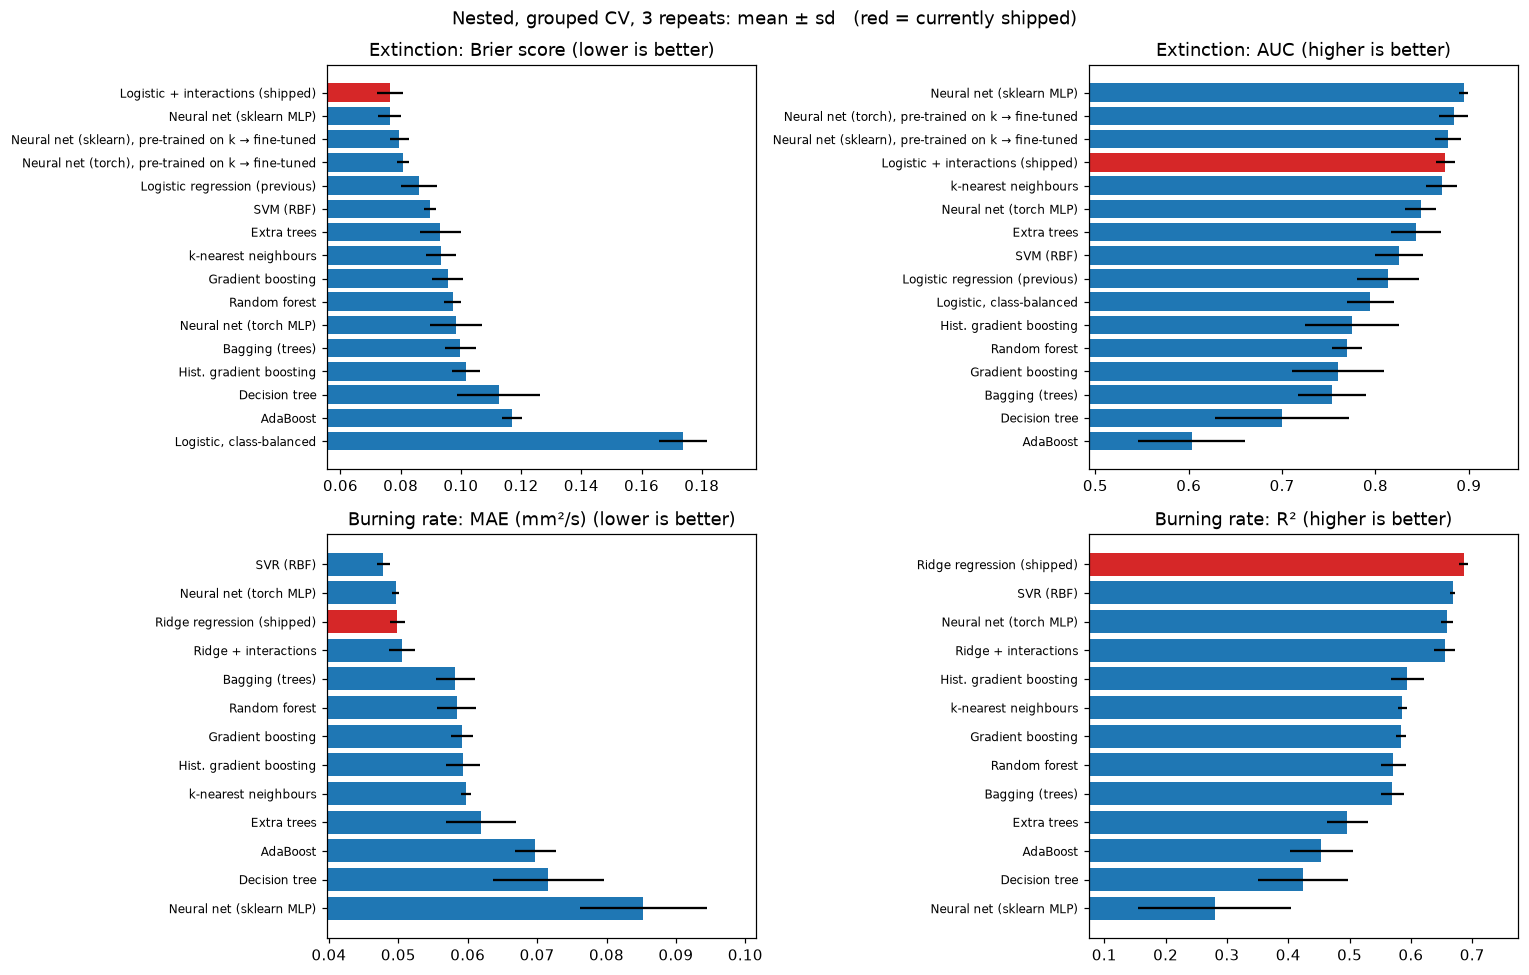

In [13]:
def bars(ax, res, col, title, better):
    r = res.drop(index=[i for i in res.index if i.startswith("Naive")])
    colors = ["#d62728" if "shipped" in i else "#1f77b4" for i in r.index]
    ax.barh(r.index, r[col], xerr=r[col + " sd"], color=colors)
    ax.invert_yaxis(); ax.set_title(f"{title} ({better} is better)"); ax.tick_params(axis="y", labelsize=8)
    lo = (r[col] - r[col + " sd"]).min(); hi = (r[col] + r[col + " sd"]).max(); pad = (hi - lo) * .15
    ax.set_xlim(lo - pad, hi + pad)

fig, ax = plt.subplots(2, 2, figsize=(14, 9))
bars(ax[0, 0], clf_res, "Brier", "Extinction: Brier score", "lower")
bars(ax[0, 1], clf_res.sort_values("AUC", ascending=False), "AUC", "Extinction: AUC", "higher")
bars(ax[1, 0], reg_res, "MAE", "Burning rate: MAE (mm²/s)", "lower")
bars(ax[1, 1], reg_res.sort_values("R²", ascending=False), "R²", "Burning rate: R²", "higher")
fig.suptitle("Nested, grouped CV, 3 repeats: mean ± sd   (red = currently shipped)")
plt.tight_layout(); plt.show()

In [14]:
def verdict(res, main, lower, ship):
    best = res[main].idxmin() if lower else res[main].idxmax()
    b, s = res.loc[best], res.loc[ship]
    gap = (s[main] - b[main]) if lower else (b[main] - s[main])
    noise = max(b[main + " sd"], s[main + " sd"])
    print(f"  best by {main}: {best} ({b[main]:.4f})   baseline: {s[main]:.4f}   improvement {gap:.4f} vs repeat-to-repeat sd {noise:.4f}"
          + ("  -> clear win" if gap > 2 * noise else "  -> within noise"))

print("Extinction (vs the previous plain logistic model)")
verdict(clf_res, "Brier", True, "Logistic regression (previous)"); verdict(clf_res, "AUC", False, "Logistic regression (previous)")
print("Burning rate"); verdict(reg_res, "MAE", True, "Ridge regression (shipped)"); verdict(reg_res, "R²", False, "Ridge regression (shipped)")

Extinction (vs the previous plain logistic model)
  best by Brier: Logistic + interactions (shipped) (0.0764)   baseline: 0.0860   improvement 0.0096 vs repeat-to-repeat sd 0.0060  -> within noise
  best by AUC: Neural net (sklearn MLP) (0.8948)   baseline: 0.8136   improvement 0.0811 vs repeat-to-repeat sd 0.0334  -> clear win
Burning rate
  best by MAE: SVR (RBF) (0.0478)   baseline: 0.0498   improvement 0.0020 vs repeat-to-repeat sd 0.0011  -> within noise
  best by R²: Ridge regression (shipped) (0.6864)   baseline: 0.6864   improvement 0.0000 vs repeat-to-repeat sd 0.0074  -> within noise


### How to read this

* **Picking the top row is slightly optimistic.** With 14 candidates, the best score is partly luck. A model is only worth
  switching to if it beats the shipped one by clearly more than the repeat-to-repeat spread. The `verdict` cell checks this
  (> 2 sd).
* **Bagging vs boosting on ~200 rows:** forests average away variance and rarely overfit badly. Boosting can fit interactions
  but needs tuning and is unstable on small data. The linear model's advantage is that the physics here is mostly *monotone*:
  more O2 → hotter flame → less extinction, so a smooth model with few parameters is hard to beat.
* **Neural nets** need far more than ~200 examples to shine. The pre-train → fine-tune variant tests whether burning-rate data
  helps the extinction task. The table shows whether it does.
* **Deploying a non-linear winner:** the ML service currently evaluates *linear* ensembles with NumPy (`_ensemble` in
  `services/ml/app.py`). A tree, SVM or torch model would need the service to load a pickled model (`joblib`/`torch`) and add
  those packages to its image. This is worth doing only if the verdict shows a clear win.

## 5. Final models: bootstrap ensembles

`build.train` refits the shipped models on **all** the data: the regularisation strength *C* of the extinction model is picked
by grouped CV, then each model is fit 40 times on bootstrap resamples. At prediction time the app averages the 40 members and
reports the 5–95% spread as an uncertainty band.

The extinction model has 27 inputs: the 6 features plus their 21 pairwise products. Coefficients are on standardised inputs,
so their sizes are comparable. Positive values push toward extinction or a faster burn.

extinction model: C = 1.0 | 27 inputs | 40 bootstrap members


,mean,sd
extinction: 12 largest terms,,
heptane x d0,1.652,0.349
heptane x co2,1.163,0.287
heptane x p_atm,-0.965,0.313
heptane x o2,-0.795,0.226
p_atm x d0,0.786,0.332
o2,-0.625,0.181
heptane,-0.621,0.114
heptane^2,-0.621,0.114
d0,0.611,0.177


,mean,sd
burn rate,,
heptane,0.016,0.005
o2,0.092,0.008
p_atm,0.009,0.005
co2,-0.025,0.006
he,0.056,0.007
d0,-0.046,0.009


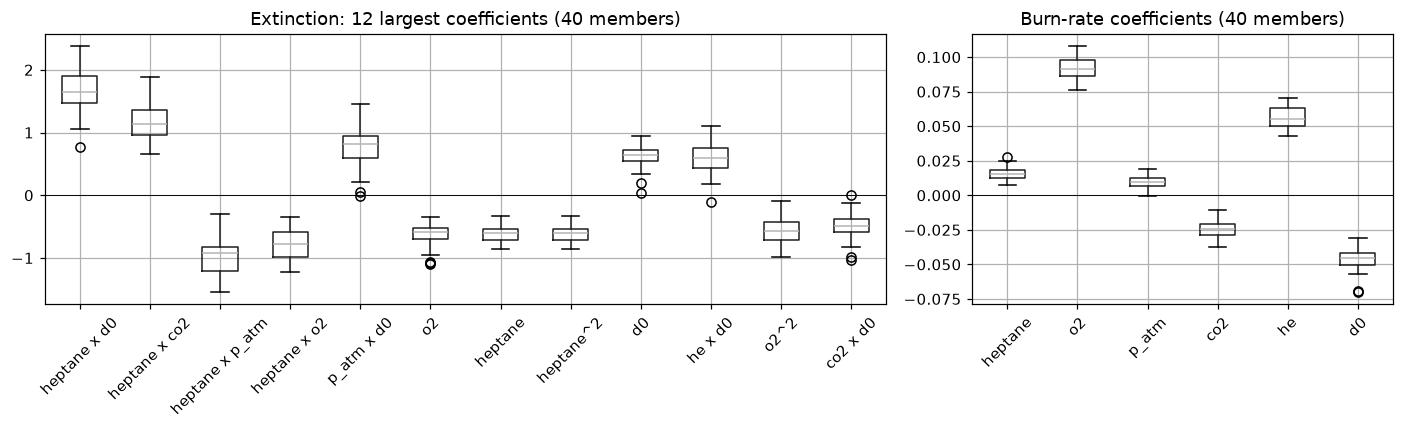

In [15]:
models, core = B.train(d)          # same code path as pipeline/build.py (with any FLEX-2 runs merged in section 2)
ext, br = models["extinction"], models["burn_rate"]
print("extinction model: C =", models["extinction_C"], "|", len(models["extinction_terms"]), "inputs |", len(ext), "bootstrap members")
ce = pd.DataFrame([m["coef"] for m in ext], columns=models["extinction_term_names"])
cb = pd.DataFrame([m["coef"] for m in br], columns=FEATS)
top = ce.mean().abs().sort_values(ascending=False).index[:12]
display(pd.DataFrame({"mean": ce[top].mean(), "sd": ce[top].std()}).round(3).rename_axis("extinction: 12 largest terms"))
display(pd.DataFrame({"mean": cb.mean(), "sd": cb.std()}).round(3).rename_axis("burn rate"))
fig, ax = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [2, 1]})
ce[top].boxplot(ax=ax[0], rot=45); ax[0].axhline(0, c="k", lw=.6); ax[0].set_title("Extinction: 12 largest coefficients (40 members)")
cb.boxplot(ax=ax[1], rot=45); ax[1].axhline(0, c="k", lw=.6); ax[1].set_title("Burn-rate coefficients (40 members)")
plt.tight_layout(); plt.show()

In [16]:
# Sanity check: run the ensembles exactly as services/ml/app.py does, for one example condition.
import math
def ensemble(members, x, clf):
    v = np.array([sum(c * (a - m) / s for c, a, m, s in zip(e["coef"], x, e["mean"], e["scale"])) + e["b"] for e in members])
    v = 1 / (1 + np.exp(-v)) if clf else np.maximum(v, 0)
    return v.mean(), np.quantile(v, .05), np.quantile(v, .95)

x = [1.0, 0.21, 1.0, 0.0, 0.0, 3.0]   # heptane, 21% O2, 1 atm, no CO2/He, 3 mm droplet
x_ext = [math.prod(x[j] for j in t) for t in models["extinction_terms"]]
print("P(extinction) mean %.2f  [%.2f, %.2f]" % ensemble(ext, x_ext, True))
print("k (mm²/s)     mean %.3f  [%.3f, %.3f]" % ensemble(br, x, False))

P(extinction) mean 0.54  [0.38, 0.70]
k (mm²/s)     mean 0.533  [0.517, 0.550]


## 6. Save for the web app

Writes `data/build/models.json` and `data/build/report.json` in the format `services/ml/app.py` reads. The row counts in
`report.json` (from `pipeline/build.py`) are kept, and the section-4b comparison is stored under `comparison`.

> `python pipeline/build.py` retrains from the PSI-69 table and overwrites these files. If you merged FLEX-2 runs here,
> re-run this notebook after any rebuild.

In [17]:
old = json.loads((OUT / "report.json").read_text()) if (OUT / "report.json").exists() else {}
L = clf_scores.loc["Logistic + interactions (shipped)"]
report = {**core, "rows": old.get("rows"), "training_sources": dd.source.value_counts().to_dict()}
report["extinction"].update(shipped_accuracy=L["accuracy@0.5"], shipped_balanced_accuracy=L["balanced acc@0.5"])
report["burn_rate"]["shipped_rmse"] = reg_scores.loc["Ridge regression (shipped)", "RMSE (mm²/s)"]
report["comparison"] = {
    "protocol": "nested CV: 5 grouped folds (by test date) x 3 shuffled repeats; inner 3-fold grouped grid search",
    "extinction": clf_res.drop(columns="seconds").round(4).to_dict("index"),
    "burn_rate": reg_res.drop(columns="seconds").round(4).to_dict("index"),
}
(OUT / "models.json").write_text(json.dumps(B.clean(models), separators=(",", ":")))
(OUT / "report.json").write_text(json.dumps(B.clean(report), indent=1))
print("saved", OUT / "models.json", "and", OUT / "report.json")
print("next: docker compose up --build -d ml   (the ml image copies data/build at build time)")

saved /repo/data/build/models.json and /repo/data/build/report.json
next: docker compose up --build -d ml   (the ml image copies data/build at build time)
